In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

from pathlib import Path

In [3]:
df = pd.read_excel("server_anomaly_detection_dataset.xlsx")

df["timestamp"] = pd.to_datetime(df["timestamp"])

df["is_anomaly"] = (
    df["is_anomaly"]
    .astype(str)
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
)

print(df.head())

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

            timestamp  cpu_usage  is_anomaly anomaly_type event_id
0 2026-03-04 00:00:00  30.857864       False       normal      NaN
1 2026-03-04 00:05:00  31.086959       False       normal      NaN
2 2026-03-04 00:10:00  30.561144       False       normal      NaN
3 2026-03-04 00:15:00  31.150289       False       normal      NaN
4 2026-03-04 00:20:00  27.737905       False       normal      NaN

Dataset shape: (4032, 5)

Missing values:
timestamp          0
cpu_usage          0
is_anomaly         0
anomaly_type       0
event_id        3969
dtype: int64


In [4]:
print(df["anomaly_type"].value_counts())

anomaly_type
normal         3969
spike            30
level_shift      24
outage            9
Name: count, dtype: int64


In [5]:
WINDOW = 36

Z_THRESHOLD = 3.5

CPU_THRESHOLD = 80

print("Rolling window:", WINDOW)
print("Z-score threshold:", Z_THRESHOLD)
print("Fixed CPU threshold:", CPU_THRESHOLD)

Rolling window: 36
Z-score threshold: 3.5
Fixed CPU threshold: 80


In [6]:
df["rolling_mean"] = (
    df["cpu_usage"]
    .shift(1)
    .rolling(
        window=WINDOW,
        min_periods=WINDOW
    )
    .mean()
)

print(df[["timestamp", "cpu_usage", "rolling_mean"]].head(40))

             timestamp  cpu_usage  rolling_mean
0  2026-03-04 00:00:00  30.857864           NaN
1  2026-03-04 00:05:00  31.086959           NaN
2  2026-03-04 00:10:00  30.561144           NaN
3  2026-03-04 00:15:00  31.150289           NaN
4  2026-03-04 00:20:00  27.737905           NaN
5  2026-03-04 00:25:00  30.453123           NaN
6  2026-03-04 00:30:00  29.950931           NaN
7  2026-03-04 00:35:00  27.020270           NaN
8  2026-03-04 00:40:00  24.789976           NaN
9  2026-03-04 00:45:00  23.461290           NaN
10 2026-03-04 00:50:00  23.751350           NaN
11 2026-03-04 00:55:00  27.644512           NaN
12 2026-03-04 01:00:00  29.314209           NaN
13 2026-03-04 01:05:00  27.358200           NaN
14 2026-03-04 01:10:00  26.102248           NaN
15 2026-03-04 01:15:00  30.227200           NaN
16 2026-03-04 01:20:00  30.578214           NaN
17 2026-03-04 01:25:00  27.309611           NaN
18 2026-03-04 01:30:00  26.592490           NaN
19 2026-03-04 01:35:00  25.541308       

In [7]:
df["rolling_std"] = (
    df["cpu_usage"]
    .shift(1)
    .rolling(
        window=WINDOW,
        min_periods=WINDOW
    )
    .std()
)

print(df[["cpu_usage", "rolling_std"]].head(40))

    cpu_usage  rolling_std
0   30.857864          NaN
1   31.086959          NaN
2   30.561144          NaN
3   31.150289          NaN
4   27.737905          NaN
5   30.453123          NaN
6   29.950931          NaN
7   27.020270          NaN
8   24.789976          NaN
9   23.461290          NaN
10  23.751350          NaN
11  27.644512          NaN
12  29.314209          NaN
13  27.358200          NaN
14  26.102248          NaN
15  30.227200          NaN
16  30.578214          NaN
17  27.309611          NaN
18  26.592490          NaN
19  25.541308          NaN
20  26.018110          NaN
21  27.706874          NaN
22  26.363164          NaN
23  26.800067          NaN
24  27.418653          NaN
25  28.182475          NaN
26  25.778802          NaN
27  25.123535          NaN
28  29.092096          NaN
29  27.133784          NaN
30  26.371538          NaN
31  26.721031          NaN
32  24.882879          NaN
33  24.147390          NaN
34  27.838233          NaN
35  29.289190          NaN
3

In [8]:
df["z_score"] = (
    df["cpu_usage"] - df["rolling_mean"]
) / df["rolling_std"]

df["z_score"] = df["z_score"].replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    df[
        [
            "timestamp",
            "cpu_usage",
            "rolling_mean",
            "rolling_std",
            "z_score"
        ]
    ].head(40)
)

             timestamp  cpu_usage  rolling_mean  rolling_std   z_score
0  2026-03-04 00:00:00  30.857864           NaN          NaN       NaN
1  2026-03-04 00:05:00  31.086959           NaN          NaN       NaN
2  2026-03-04 00:10:00  30.561144           NaN          NaN       NaN
3  2026-03-04 00:15:00  31.150289           NaN          NaN       NaN
4  2026-03-04 00:20:00  27.737905           NaN          NaN       NaN
5  2026-03-04 00:25:00  30.453123           NaN          NaN       NaN
6  2026-03-04 00:30:00  29.950931           NaN          NaN       NaN
7  2026-03-04 00:35:00  27.020270           NaN          NaN       NaN
8  2026-03-04 00:40:00  24.789976           NaN          NaN       NaN
9  2026-03-04 00:45:00  23.461290           NaN          NaN       NaN
10 2026-03-04 00:50:00  23.751350           NaN          NaN       NaN
11 2026-03-04 00:55:00  27.644512           NaN          NaN       NaN
12 2026-03-04 01:00:00  29.314209           NaN          NaN       NaN
13 202

In [9]:
df["z_alert"] = (
    df["z_score"].abs() > Z_THRESHOLD
).fillna(False)

print(
    "Total Z-score alerts:",
    int(df["z_alert"].sum())
)

Total Z-score alerts: 41


In [10]:
df["fixed_alert"] = (
    df["cpu_usage"] > CPU_THRESHOLD
)

print(
    "Total fixed-limit alerts:",
    int(df["fixed_alert"].sum())
)

Total fixed-limit alerts: 30


In [11]:
def evaluate_detector(actual, predicted):

    actual = np.asarray(actual, dtype=bool)
    predicted = np.asarray(predicted, dtype=bool)

    TP = int(np.sum(actual & predicted))
    FP = int(np.sum(~actual & predicted))
    FN = int(np.sum(actual & ~predicted))
    TN = int(np.sum(~actual & ~predicted))

    precision = (
        TP / (TP + FP)
        if TP + FP > 0
        else 0.0
    )

    recall = (
        TP / (TP + FN)
        if TP + FN > 0
        else 0.0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "precision": precision,
        "recall": recall
    }

In [12]:
z_results = evaluate_detector(
    df["is_anomaly"],
    df["z_alert"]
)

print("ROLLING Z-SCORE RESULTS")
print(z_results)

ROLLING Z-SCORE RESULTS
{'TP': 32, 'FP': 9, 'FN': 31, 'TN': 3960, 'precision': 0.7804878048780488, 'recall': 0.5079365079365079}


In [13]:
fixed_results = evaluate_detector(
    df["is_anomaly"],
    df["fixed_alert"]
)

print("\nFIXED CPU LIMIT RESULTS")
print(fixed_results)


FIXED CPU LIMIT RESULTS
{'TP': 30, 'FP': 0, 'FN': 33, 'TN': 3969, 'precision': 1.0, 'recall': 0.47619047619047616}


In [14]:
z_thresholds = np.arange(
    1.5,
    8.01,
    0.25
)

z_sweep_results = []

for threshold in z_thresholds:

    predictions = (
        df["z_score"].abs() > threshold
    ).fillna(False)

    metrics = evaluate_detector(
        df["is_anomaly"],
        predictions
    )

    z_sweep_results.append({
        "threshold": float(threshold),
        **metrics
    })

z_sweep_df = pd.DataFrame(
    z_sweep_results
)

print(z_sweep_df.head())

   threshold  TP    FP  FN    TN  precision    recall
0       1.50  44  1428  19  2541   0.029891  0.698413
1       1.75  43   956  20  3013   0.043043  0.682540
2       2.00  38   609  25  3360   0.058733  0.603175
3       2.25  36   354  27  3615   0.092308  0.571429
4       2.50  35   185  28  3784   0.159091  0.555556


In [15]:
cpu_thresholds = np.arange(
    50,
    101,
    2
)

cpu_sweep_results = []

for threshold in cpu_thresholds:

    predictions = (
        df["cpu_usage"] > threshold
    )

    metrics = evaluate_detector(
        df["is_anomaly"],
        predictions
    )

    cpu_sweep_results.append({
        "threshold": int(threshold),
        **metrics
    })

cpu_sweep_df = pd.DataFrame(
    cpu_sweep_results
)

print(cpu_sweep_df.head())

   threshold  TP    FP  FN    TN  precision   recall
0         50  30  1643  33  2326   0.017932  0.47619
1         52  30  1503  33  2466   0.019569  0.47619
2         54  30  1354  33  2615   0.021676  0.47619
3         56  30  1213  33  2756   0.024135  0.47619
4         58  30  1050  33  2919   0.027778  0.47619


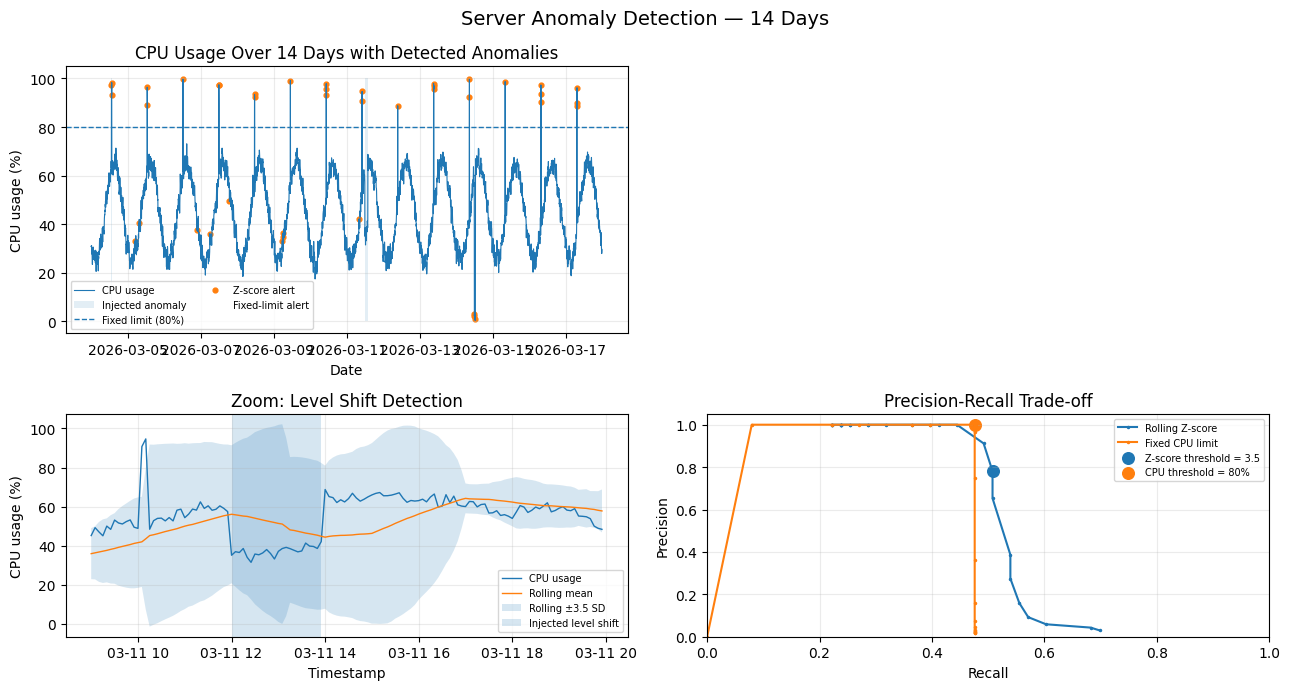

In [16]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 7),
    gridspec_kw={
        "height_ratios": [1.2, 1]
    }
)

ax1 = axes[0, 0]
ax2 = axes[1, 0]
ax3 = axes[1, 1]

ax1.plot(
    df["timestamp"],
    df["cpu_usage"],
    linewidth=0.8,
    label="CPU usage"
)
anomaly_mask = df["is_anomaly"].to_numpy()

ax1.fill_between(
    df["timestamp"],
    0,
    100,
    where=anomaly_mask,
    alpha=0.12,
    label="Injected anomaly"
)
ax1.axhline(
    CPU_THRESHOLD,
    linestyle="--",
    linewidth=1,
    label="Fixed limit (80%)"
)
z_mask = df["z_alert"]

ax1.scatter(
    df.loc[z_mask, "timestamp"],
    df.loc[z_mask, "cpu_usage"],
    s=12,
    label="Z-score alert"
)
fixed_mask = df["fixed_alert"]

ax1.scatter(
    df.loc[fixed_mask, "timestamp"],
    df.loc[fixed_mask, "cpu_usage"],
    s=15,
    marker="o",
    facecolors="none",
    label="Fixed-limit alert"
)

ax1.set_title(
    "CPU Usage Over 14 Days with Detected Anomalies"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("CPU usage (%)")

ax1.grid(True, alpha=0.25)
ax1.legend(fontsize=7, ncol=2)

level_indices = np.where(
    df["anomaly_type"].to_numpy() == "level_shift"
)[0]

if len(level_indices) > 0:

    level_start = level_indices[0]
    level_end = level_indices[-1] + 1

    zoom_start = max(
        0,
        level_start - 36
    )

    zoom_end = min(
        len(df),
        level_end + 72
    )

    zoom_df = df.iloc[
        zoom_start:zoom_end
    ]

    ax2.plot(
        zoom_df["timestamp"],
        zoom_df["cpu_usage"],
        linewidth=1,
        label="CPU usage"
    )

    ax2.plot(
        zoom_df["timestamp"],
        zoom_df["rolling_mean"],
        linewidth=1,
        label="Rolling mean"
    )
    lower_band = (
        zoom_df["rolling_mean"]
        - 3.5 * zoom_df["rolling_std"]
    )

    upper_band = (
        zoom_df["rolling_mean"]
        + 3.5 * zoom_df["rolling_std"]
    )
    ax2.fill_between(
        zoom_df["timestamp"],
        lower_band,
        upper_band,
        alpha=0.18,
        label="Rolling ±3.5 SD"
    )
    ax2.axvspan(
        df.loc[level_start, "timestamp"],
        df.loc[level_end - 1, "timestamp"],
        alpha=0.18,
        label="Injected level shift"
    )
    ax2.set_title(
        "Zoom: Level Shift Detection"
    )
    ax2.set_xlabel("Timestamp")
    ax2.set_ylabel("CPU usage (%)")

    ax2.grid(True, alpha=0.25)
    ax2.legend(fontsize=7)
    
ax3.plot(
    z_sweep_df["recall"],
    z_sweep_df["precision"],
    marker=".",
    markersize=3,
    label="Rolling Z-score"
)

ax3.plot(
    cpu_sweep_df["recall"],
    cpu_sweep_df["precision"],
    marker=".",
    markersize=3,
    label="Fixed CPU limit"
)
z_default = z_sweep_df[
    np.isclose(
        z_sweep_df["threshold"],
        Z_THRESHOLD
    )
]

if not z_default.empty:

    ax3.scatter(
        z_default["recall"],
        z_default["precision"],
        s=70,
        label="Z-score threshold = 3.5"
    )
cpu_default = cpu_sweep_df[
    cpu_sweep_df["threshold"] == CPU_THRESHOLD
]

if not cpu_default.empty:

    ax3.scatter(
        cpu_default["recall"],
        cpu_default["precision"],
        s=70,
        label="CPU threshold = 80%"
    )

ax3.set_title(
    "Precision-Recall Trade-off"
)

ax3.set_xlabel("Recall")
ax3.set_ylabel("Precision")

ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1.05)

ax3.grid(True, alpha=0.25)
ax3.legend(fontsize=7)

axes[0, 1].axis("off")

fig.suptitle(
    "Server Anomaly Detection — 14 Days",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "chart.png",
    dpi=120,
    bbox_inches="tight"
)

plt.show()